In [11]:
import sys
import os
from pathlib import Path

def find_project_root(start):
    for base in [start, *start.parents]:
        for candidate in [base, base / "barrier-extraction"]:
            if (candidate / "src").is_dir() and (candidate / "data").is_dir():
                return candidate
    raise FileNotFoundError("Could not locate barrier-extraction project root containing src/ and data/.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
PLOT_DIR = PROJECT_ROOT / "plots"
PLOT_DIR.mkdir(exist_ok=True)


import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel
from src.utils import barrier_dist, paper_three_point_barrier
try:
    import scienceplots
    plt.style.use(["science", "notebook", "ieee", "grid"])
except ModuleNotFoundError:
    plt.style.use("default")

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 16,
    "axes.titlesize": 17,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.2,
    "lines.linewidth": 2.0,
})


In [12]:
# D3-penalized BNN experimental-data plotting setup.
EXPERIMENTS7_RESULTS = PROJECT_ROOT / "data" / "results" / "experiments7_models_d3lam1e1"
EXPERIMENTS7_PREFIX = "experiments7"
EXPERIMENTS7_SUFFIX = "bnn_d3lam1e1"

MODEL_SPECS = [
    ("Changepoint of Safe Products", "changepoint_of_safe_products"),
    ("Sum of Changepoints", "sum_of_changepoints"),
]

EXPERIMENT_SPECS = [
    {
        "key": "Aljuwaire1984",
        "label": "Aljuwaire et al. 1984",
        "system": r"$^{48}$Ca+$^{40}$Ca",
        "short_label": "Aljuwaire",
        "E_file": "E_Aljuwairetal.1984.npy",
        "sigma_file": "sigma_Aljuwairetal.1984.npy",
        "error_file": "error_Aljuwairetal.1984.npy",
        "xlims": None,
        "ylims": [-50, 1000],
    },
    {
        "key": "Dasgupta2007",
        "label": "Dasgupta et al. 2007",
        "system": r"$^{208}$Pb+$^{16}$O",
        "short_label": "Dasgupta",
        "E_file": "E_Dasguptaetal.2007.npy",
        "sigma_file": "sigma_Dasguptaetal.2007.npy",
        "error_file": "error_Dasguptaetal.2007.npy",
        "xlims": None,
        "ylims": [-50, 1200],
    },
    {
        "key": "Jiang2010",
        "label": "Jiang et al. 2010",
        "system": r"$^{48}$Ca+$^{40}$Ca",
        "short_label": "Jiang",
        "E_file": "E_Jiangetal.2010.npy",
        "sigma_file": "sigma_Jiangetal.2010.npy",
        "error_file": "error_Jiangetal.2010.npy",
        "xlims": None,
        "ylims": [-100, 1000],
    },
    {
        "key": "Montagnoli2012",
        "label": "Montagnoli et al. 2012",
        "system": r"$^{40}$Ca+$^{40}$Ca",
        "short_label": "Montagnoli",
        "E_file": "E_Montagnolietal.2012.npy",
        "sigma_file": "sigma_Montagnolietal.2012.npy",
        "error_file": "error_Montagnolietal.2012.npy",
        "xlims": None,
        "ylims": [-100, 2000],
    },
    {
        "key": "Morton1999",
        "label": "Morton et al. 1999",
        "system": r"$^{208}$Pb+$^{16}$O",
        "short_label": "Morton",
        "E_file": "E_Mortonetal.1999.npy",
        "sigma_file": "sigma_Mortonetal.1999.npy",
        "error_file": "error_Mortonetal.1999.npy",
        "xlims": None,
        "ylims": [-100, 1000],
    },
    {
        "key": "Stefanini2009",
        "label": "Stefanini et al. 2009",
        "system": r"$^{48}$Ca+$^{48}$Ca",
        "short_label": "Stefanini",
        "E_file": "E_Stefaninietal.2009.npy",
        "sigma_file": "sigma_Stefaninietal.2009.npy",
        "error_file": "error_Stefaninietal.2009.npy",
        "xlims": None,
        "ylims": [-100, 1700],
    },
    {
        "key": "Trotta2001",
        "label": "Trotta et al. 2001",
        "system": r"$^{48}$Ca+$^{40}$Ca",
        "short_label": "Trotta",
        "E_file": "E_Trottaetal.2001.npy",
        "sigma_file": "sigma_Trottaetal.2001.npy",
        "error_file": "error_Trottaetal.2001.npy",
        "xlims": None,
        "ylims": [-50, 2500],
    },
]

BNN_COLOR = "tab:green"
GP_COLOR = "tab:purple"
LINEAR_GP_COLOR = "tab:blue"
LOG_GP_COLOR = "tab:orange"
DATA_COLOR = "0.15"
BAND_ALPHA = 0.22
GP_N_RESTARTS = 20
GP_N_SAMPLES = 100
GP_BAND_SIGMA = 1.0
SHARED_LABEL_FONTSIZE = 22
SHARED_XLABEL_Y = 0.05
SHARED_YLABEL_X = 0.04
MODEL_PANEL_POSITIONS = [1, 2]


In [13]:

def finite_error_train(error_train, sigma_train, fallback_fraction=0.05):
    error_train = np.asarray(error_train, dtype=float)
    sigma_train = np.asarray(sigma_train, dtype=float)
    fallback = fallback_fraction * np.maximum(np.abs(sigma_train), 1.0)
    return np.where(np.isfinite(error_train) & (error_train > 0), error_train, fallback)


def gpbarriers_prediction_grid(E_train, spec):
    if spec["key"] in {"Morton1999", "Dasgupta2007"}:
        return np.linspace(70.0, 90.0, 200)
    if spec["key"] == "Montagnoli2012":
        return np.linspace(50.0, 60.0, 200)
    return np.linspace(E_train[0], E_train[-1], 300)


def train_gpbarriers_gp(E_train, sigma_train, error_train, spec):
    """Train the GP using the legacy GPBarriers notebook recipe."""
    E_train = np.asarray(E_train, dtype=float)
    sigma_train = np.asarray(sigma_train, dtype=float)
    error_train = np.asarray(error_train, dtype=float)

    if E_train[0] > E_train[-1]:
        E_train = E_train[::-1]
        sigma_train = sigma_train[::-1]
        error_train = error_train[::-1]

    if spec["key"] == "Stefanini2009":
        kernel = 1 * RBF(
            length_scale=1.0,
            length_scale_bounds=(5 * np.abs(E_train[1] - E_train[0]), 1e1),
        )
    else:
        kernel = 1 * RBF(
            length_scale=1.0,
            length_scale_bounds=(np.abs(E_train[1] - E_train[0]), 1e1),
        )

    if not np.isfinite(error_train[0]):
        if spec["key"] in {"Aljuwaire1984", "Trotta2001"}:
            alpha = np.zeros(error_train.shape) + 1e-6
            kernel += 1 * WhiteKernel(noise_level=1e-5, noise_level_bounds=(1e-9, 1e-5))
        else:
            alpha = np.zeros(error_train.shape) + 1e-5
            kernel += 1 * WhiteKernel(noise_level=1e-5, noise_level_bounds=(1e-9, 1e-3))
    else:
        alpha = error_train**2

    gp = GaussianProcessRegressor(kernel=kernel, alpha=alpha, n_restarts_optimizer=20)
    gp.fit(E_train.reshape(-1, 1), sigma_train)
    return gp, E_train


def train_experiment_gp(E_train, sigma_train, error_train, spec, E_eval, n_samples=GP_N_SAMPLES):
    gp, _ = train_gpbarriers_gp(E_train, sigma_train, error_train, spec)
    E_eval = np.asarray(E_eval, dtype=float)
    sigma_samples = gp.sample_y(E_eval.reshape(-1, 1), n_samples)
    d_samples = np.zeros((len(E_eval), n_samples))
    for j in range(n_samples):
        d_samples[:, j] = barrier_dist(E_eval, sigma_samples[:, j], acc=4)
    d_mean = d_samples.mean(axis=1)
    d_median = np.median(d_samples, axis=1)
    d_std = d_samples.std(axis=1)
    d_low, d_high = np.percentile(d_samples, [16.0, 84.0], axis=1)
    return {
        "gp": gp,
        "E_eval": E_eval,
        "d_mean": d_mean,
        "d_median": d_median,
        "d_std": d_std,
        "d_low": d_low,
        "d_high": d_high,
    }


def _first_h5_group(h5_file):
    return h5_file[sorted(h5_file.keys(), key=lambda key: int(key) if key.isdigit() else key)[0]]


def experiments7_result_path(experiment_key, model_slug):
    filename = f"{EXPERIMENTS7_PREFIX}_{experiment_key}_{model_slug}_{EXPERIMENTS7_SUFFIX}.h5"
    return os.path.join(EXPERIMENTS7_RESULTS, filename)


def load_experiment_data(spec):
    E_train = np.load(DATA_DIR / spec["E_file"])
    sigma_train = np.load(DATA_DIR / spec["sigma_file"])
    error_train = np.load(DATA_DIR / spec["error_file"])
    return E_train, sigma_train, error_train


def load_experiments7_bnn_case(experiment_key):
    preds = {}
    E_pred_by_model = {}

    for model_name, model_slug in MODEL_SPECS:
        with h5py.File(experiments7_result_path(experiment_key, model_slug), "r") as f:
            group = _first_h5_group(f)
            preds[model_name] = group["d2_samples"][()]
            E_pred_by_model[model_name] = group["x_pred"][()]

    return {
        "experiment_key": experiment_key,
        "preds": preds,
        "E_pred_by_model": E_pred_by_model,
    }


def add_panel_label(ax, label, loc="upper left"):
    if loc == "lower left":
        x, y, va = 0.03, 0.08, "bottom"
    else:
        x, y, va = 0.03, 0.92, "top"
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="left",
        va=va,
        fontsize=11,
    )


def experiment_legend_handles(center="mean"):
    return [
        plt.Line2D([], [], color=GP_COLOR, lw=2.0, ls="--", label=f"GP {center}"),
        plt.Rectangle((0, 0), 1, 1, color=GP_COLOR, alpha=BAND_ALPHA, label="GP 68% band"),
        plt.Line2D([], [], color=BNN_COLOR, lw=2.0, ls="--", label=f"BNN {center}"),
        plt.Rectangle((0, 0), 1, 1, color=BNN_COLOR, alpha=BAND_ALPHA, label="BNN 68% CI"),
        plt.Line2D([], [], marker="o", color=DATA_COLOR, lw=0, markersize=4, label="3-point"),
    ]


def add_inset_legend(ax, handles):
    ax.legend(
        handles=handles,
        loc="upper right",
        bbox_to_anchor=(0.98, 0.98),
        bbox_transform=ax.transAxes,
        frameon=False,
        fontsize=9,
        handlelength=1.6,
        borderpad=0.35,
        labelspacing=0.3,
    )


def plot_finite_difference_points(ax, E_barrier, dist, err, error_train, spec, dE):
    x = E_barrier
    y = dist
    quoted_errors = np.asarray(error_train)[dE:-dE]
    has_quoted_errors = np.isfinite(quoted_errors) & (quoted_errors > 0)

    if np.all(has_quoted_errors):
        ax.errorbar(
            x,
            y,
            yerr=[err, err],
            marker="o",
            ls="",
            lw=1,
            ms=3.5,
            color=DATA_COLOR,
            label=spec["label"],
            zorder=5,
        )
    else:
        ax.plot(
            x,
            y,
            marker="o",
            ls="",
            lw=0,
            ms=3.5,
            color=DATA_COLOR,
            label=spec["label"],
            zorder=5,
        )


def plot_experiment_model_grid(spec, outfile=None, dE=3):
    E_train, sigma_train, error_train = load_experiment_data(spec)
    gp_error_train = error_train
    bnn_case = load_experiments7_bnn_case(spec["key"])
    gp_E_pred = bnn_case["E_pred_by_model"][MODEL_SPECS[0][0]]
    E_barrier, dist, err = paper_three_point_barrier(E_train, sigma_train, error_train, dE=dE)
    xlims = spec["xlims"] or [E_train.min(), E_train.max()]
    gp_case = train_experiment_gp(E_train, sigma_train, gp_error_train, spec, gp_E_pred)

    fig, axes = plt.subplots(1, 3, figsize=(10.8, 2.75), sharex=True, sharey=True)
    axes = np.asarray(axes)
    axes[1].set_title(f'{spec["system"]}, {spec["label"]}', fontsize=17, pad=10)

    ax = axes[0]
    ax.plot(gp_case["E_eval"], gp_case["d_mean"], lw=2.0, ls="--", color=GP_COLOR)
    ax.fill_between(
        gp_case["E_eval"],
        gp_case["d_mean"] - GP_BAND_SIGMA * gp_case["d_std"],
        gp_case["d_mean"] + GP_BAND_SIGMA * gp_case["d_std"],
        color=GP_COLOR,
        alpha=BAND_ALPHA,
        linewidth=0,
    )
    plot_finite_difference_points(ax, E_barrier, dist, err, error_train, spec, dE)
    add_panel_label(ax, "Gaussian Process", loc="upper left")
    ax.set_xlim(xlims)
    ax.set_ylim(spec["ylims"])
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=11)

    for panel, (model_name, _) in zip(MODEL_PANEL_POSITIONS, MODEL_SPECS):
        ax = axes[panel]
        E_pred = bnn_case["E_pred_by_model"][model_name]
        preds = bnn_case["preds"][model_name]
        d_mean = preds.mean(axis=0)
        d_low, d_high = np.percentile(preds, [16.0, 84.0], axis=0)

        ax.plot(E_pred, d_mean, lw=2.0, ls="--", color=BNN_COLOR)
        ax.fill_between(E_pred, d_low, d_high, color=BNN_COLOR, alpha=BAND_ALPHA, linewidth=0)
        plot_finite_difference_points(ax, E_barrier, dist, err, error_train, spec, dE)
        add_panel_label(ax, model_name, loc="upper left")
        ax.set_xlim(xlims)
        ax.set_ylim(spec["ylims"])
        ax.grid(True, alpha=0.25)
        ax.tick_params(labelsize=11)

    add_inset_legend(axes[1], experiment_legend_handles())
    fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=SHARED_LABEL_FONTSIZE, x=SHARED_YLABEL_X)
    fig.tight_layout(rect=[0.04, 0.12, 1, 0.98])
    fig.supxlabel(r"$E_{\mathrm{cm}}$ (MeV)", fontsize=SHARED_LABEL_FONTSIZE, y=SHARED_XLABEL_Y)

    if outfile is not None:
        fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [14]:
def plot_experiment_collection(specs, outfile=None, dE=3, gp_strategy="legacy"):
    """Plot several experiments as rows of GP and two AutoBNN model columns."""
    n_rows = len(specs)
    fig, all_axes = plt.subplots(
        n_rows, 3,
        figsize=(10.8, 2.75 * n_rows),
        squeeze=False,
    )
    fig.subplots_adjust(
        left=0.10, right=0.985,
        bottom=0.075, top=0.965,
        wspace=0.06, hspace=0.34,
    )

    for row, spec in enumerate(specs):
        axes = all_axes[row]
        E_train, sigma_train, error_train = load_experiment_data(spec)
        bnn_case = load_experiments7_bnn_case(spec["key"])
        gp_E_pred = bnn_case["E_pred_by_model"][MODEL_SPECS[0][0]]
        E_barrier, dist, err = paper_three_point_barrier(
            E_train, sigma_train, error_train, dE=dE
        )
        xlims = spec["xlims"] or [E_train.min(), E_train.max()]

        if gp_strategy == "legacy":
            gp_case = train_experiment_gp(
                E_train, sigma_train, error_train, spec, gp_E_pred
            )
            gp_panel_label = "Gaussian Process"
        elif gp_strategy == "log_unknown_fraction":
            gp_case = train_log_fraction_experiment_gp(
                E_train, sigma_train, gp_E_pred
            )
            gp_panel_label = (
                "Log GP, "
                + rf"$\tilde{{\eta}}={100 * gp_case['frac_error']:.1f}\%$"
            )
        else:
            raise ValueError("Unknown GP strategy: " + gp_strategy)

        ax = axes[0]
        ax.plot(gp_case["E_eval"], gp_case["d_median"], lw=2.0, ls="--", color=GP_COLOR)
        ax.fill_between(
            gp_case["E_eval"], gp_case["d_low"], gp_case["d_high"],
            color=GP_COLOR, alpha=BAND_ALPHA, linewidth=0,
        )
        plot_finite_difference_points(ax, E_barrier, dist, err, error_train, spec, dE)
        add_panel_label(ax, gp_panel_label, loc="upper left")

        for panel, (model_name, _) in zip(MODEL_PANEL_POSITIONS, MODEL_SPECS):
            ax_bnn = axes[panel]
            E_pred = bnn_case["E_pred_by_model"][model_name]
            preds = bnn_case["preds"][model_name]
            d_median = np.median(preds, axis=0)
            d_low, d_high = np.percentile(preds, [16.0, 84.0], axis=0)

            ax_bnn.plot(E_pred, d_median, lw=2.0, ls="--", color=BNN_COLOR)
            ax_bnn.fill_between(
                E_pred, d_low, d_high,
                color=BNN_COLOR, alpha=BAND_ALPHA, linewidth=0,
            )
            plot_finite_difference_points(
                ax_bnn, E_barrier, dist, err, error_train, spec, dE
            )
            add_panel_label(ax_bnn, model_name, loc="upper left")

        for ax_row in axes:
            ax_row.set_xlim(xlims)
            ax_row.set_ylim(spec["ylims"])
            ax_row.grid(True, alpha=0.25)
            ax_row.tick_params(labelsize=11)
        axes[1].tick_params(labelleft=False)
        axes[2].tick_params(labelleft=False)

        axes[1].set_title(f'{spec["system"]}, {spec["label"]}', fontsize=17, pad=10)
        add_inset_legend(axes[1], experiment_legend_handles(center="median"))

    fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=SHARED_LABEL_FONTSIZE, x=0.035)
    fig.supxlabel(r"$E_{\mathrm{cm}}$ (MeV)", fontsize=SHARED_LABEL_FONTSIZE, y=0.015)

    if outfile is not None:
        fig.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 3 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 6 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  

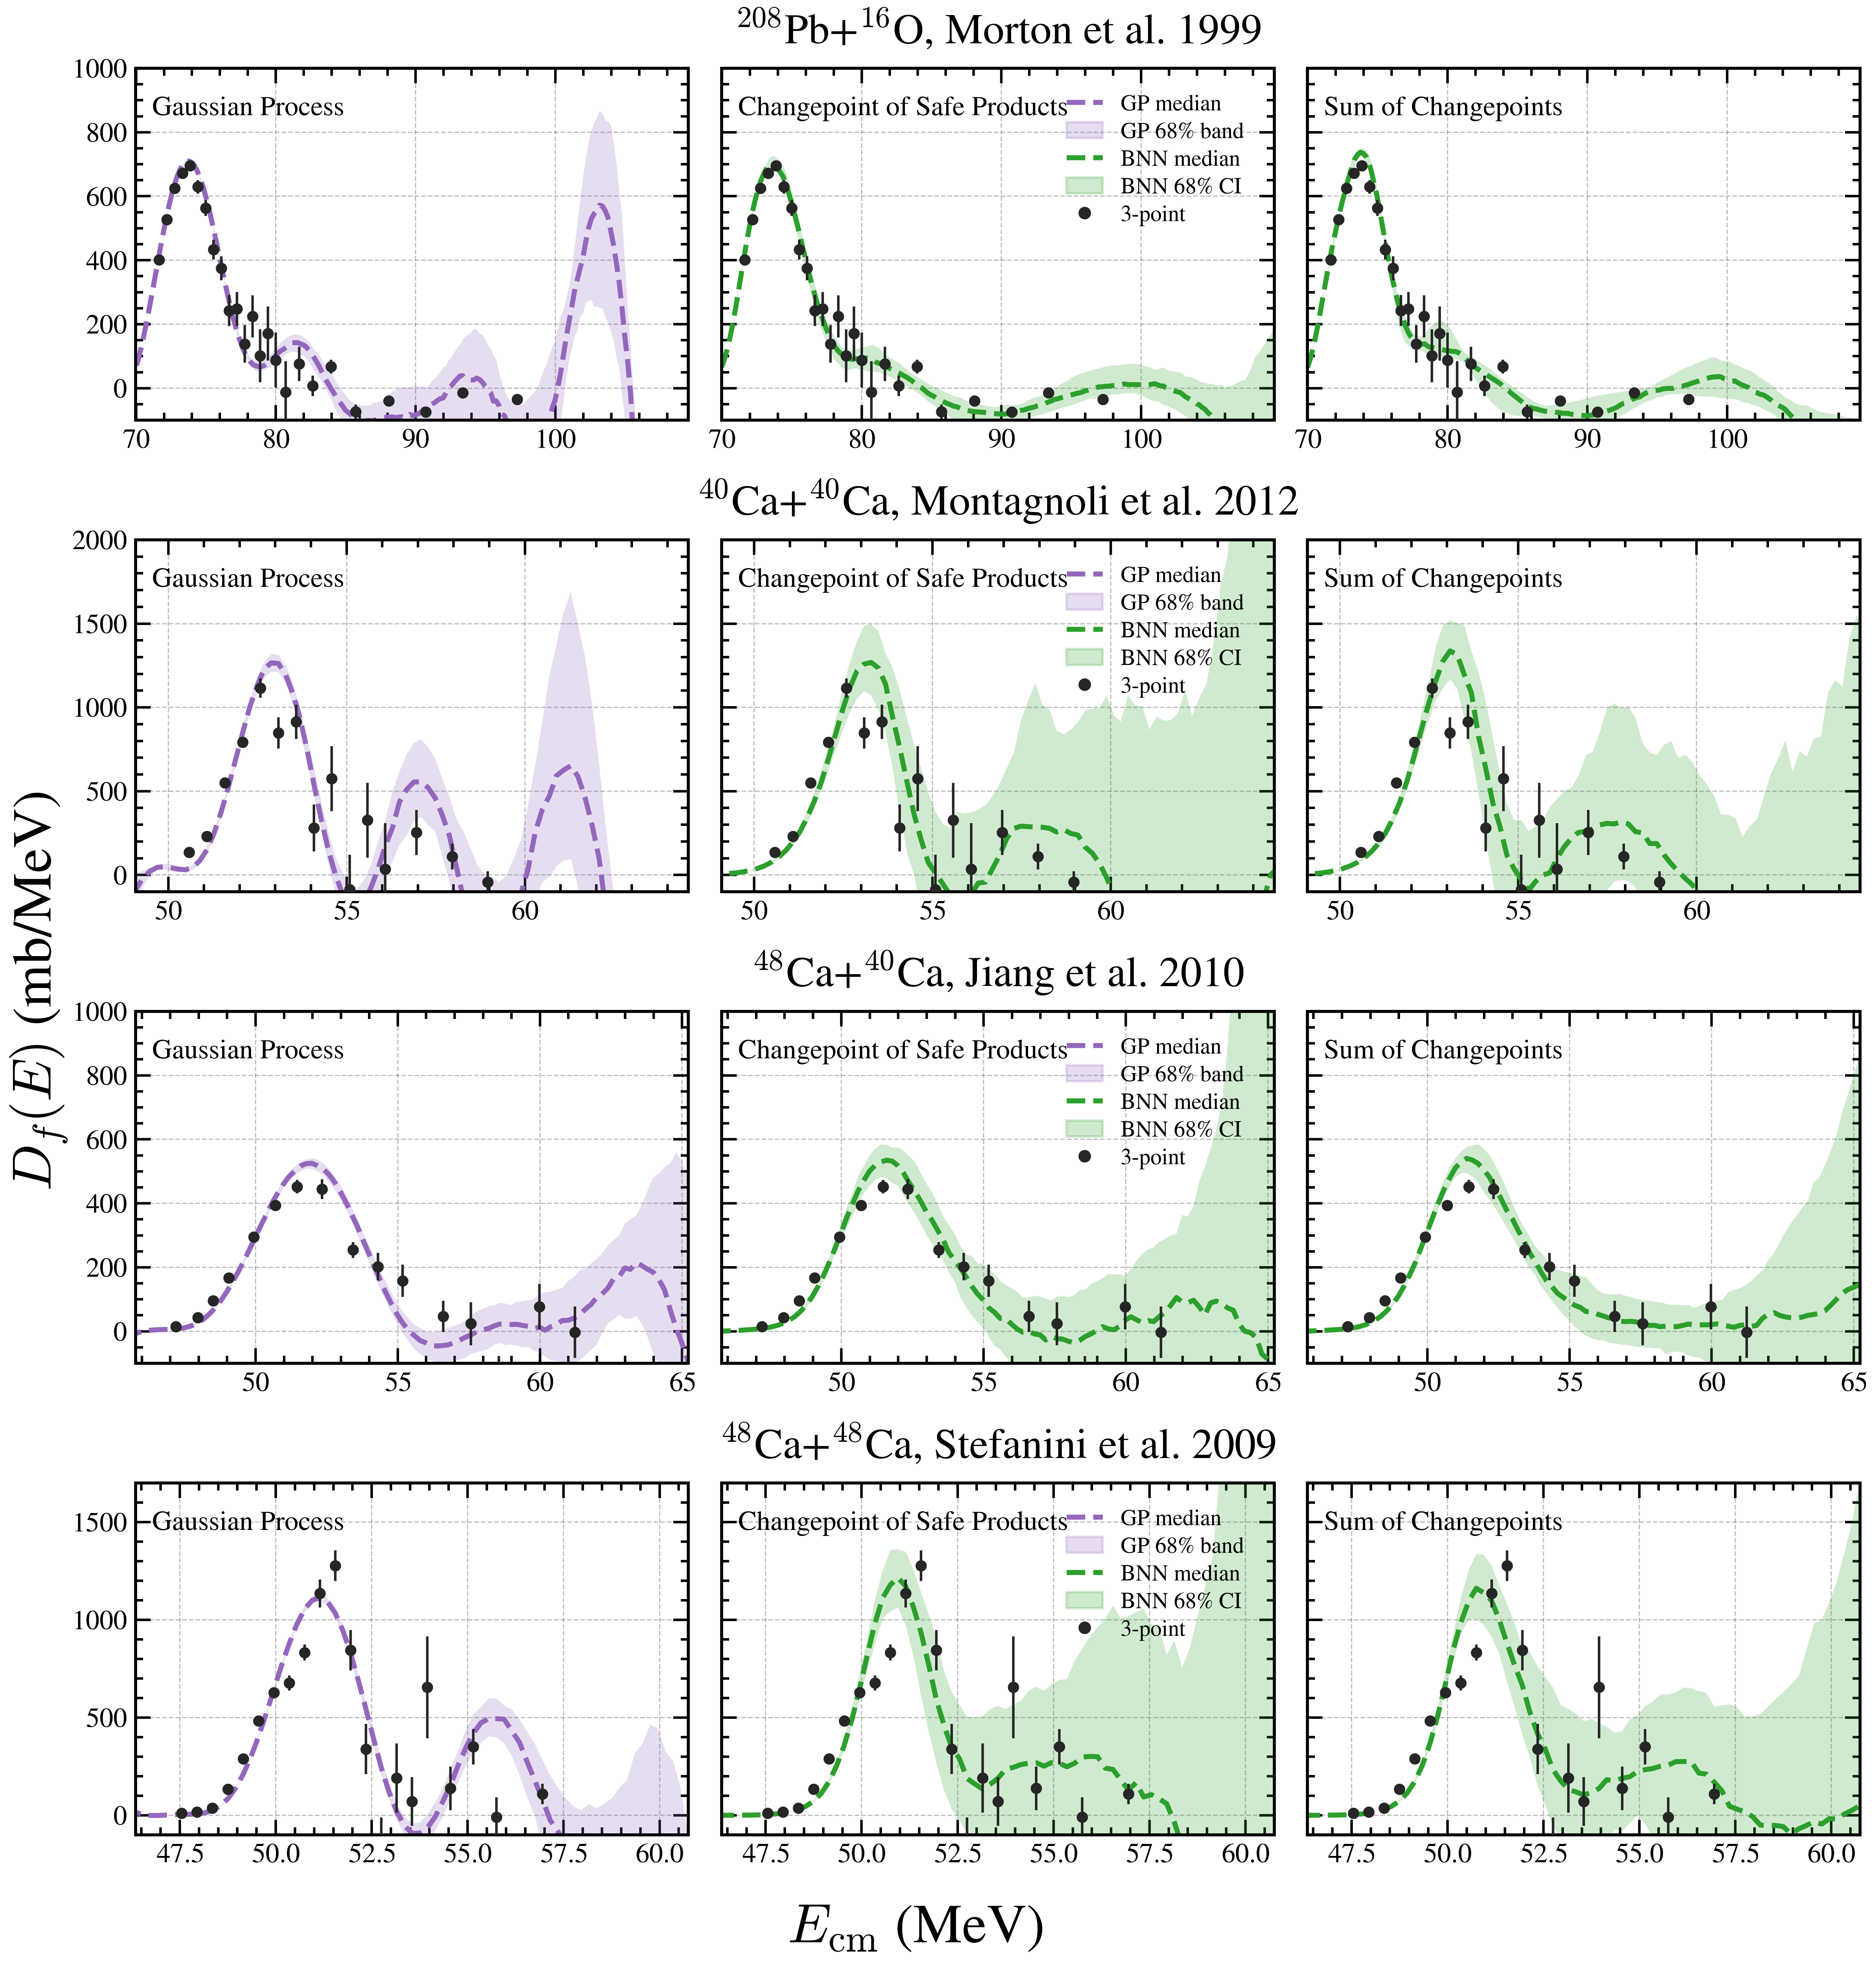

In [15]:
first_four_keys = ["Morton1999", "Montagnoli2012", "Jiang2010", "Stefanini2009"]
first_four_specs = [
    next(spec for spec in EXPERIMENT_SPECS if spec["key"] == key)
    for key in first_four_keys
]

plot_experiment_collection(
    first_four_specs,
    outfile=PLOT_DIR / "experiments7_d3lam1e1_first4_4x3.png",
)


In [16]:
remaining_three_keys = ["Dasgupta2007", "Aljuwaire1984", "Trotta2001"]
remaining_three_specs = [
    next(spec for spec in EXPERIMENT_SPECS if spec["key"] == key)
    for key in remaining_three_keys
]


## Missing experimental errors: GP diagnosis and log-space alternative

Aljuwaire (1984), Dasgupta (2007), and Trotta (2001) have only `NaN` error arrays. The legacy branch assigns nearly zero `alpha` and adds a `WhiteKernel`. It then draws from the full predictive observation process and differentiates those draws twice. The independent white noise sampled at each prediction point is amplified approximately as $1/\Delta E^2$, explaining why only these datasets develop enormous GP bands.

The same two-stage construction is possible in linear space. There, a fitted white-noise variance represents one constant absolute error in mb. In log space it represents one constant fractional error: $\log Y_i=f(E_i)+\epsilon_i$, $\epsilon_i\sim N(0,s^2)$, with $r=\sqrt{e^{s^2}-1}$. For both models, the code first estimates the noise by marginal likelihood and then refits the optimized smooth kernel with the learned noise placed in `alpha` and no `WhiteKernel`. Consequently, posterior draws are smooth latent functions rather than new noisy measurements. The distinction is scientific: constant absolute errors favor linear space; constant percentage errors favor log space.


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/

,dataset,legacy_predictive_white_sd_mb,learned_absolute_error_mb,absolute_error_over_median_sigma,learned_fractional_error,legacy_median_D_band_width,linear_median_D_band_width,log_median_D_band_width
0,Aljuwaire,0.578168,6.023718,0.106789,0.168496,48742.396610,58.413909,477.443333
1,Dasgupta,10.000000,10.748565,0.121806,0.146125,487639.898819,80.437494,640.735588
2,Trotta,1.000000,11.987450,0.060111,0.085605,90196.244087,160.072895,328.558220


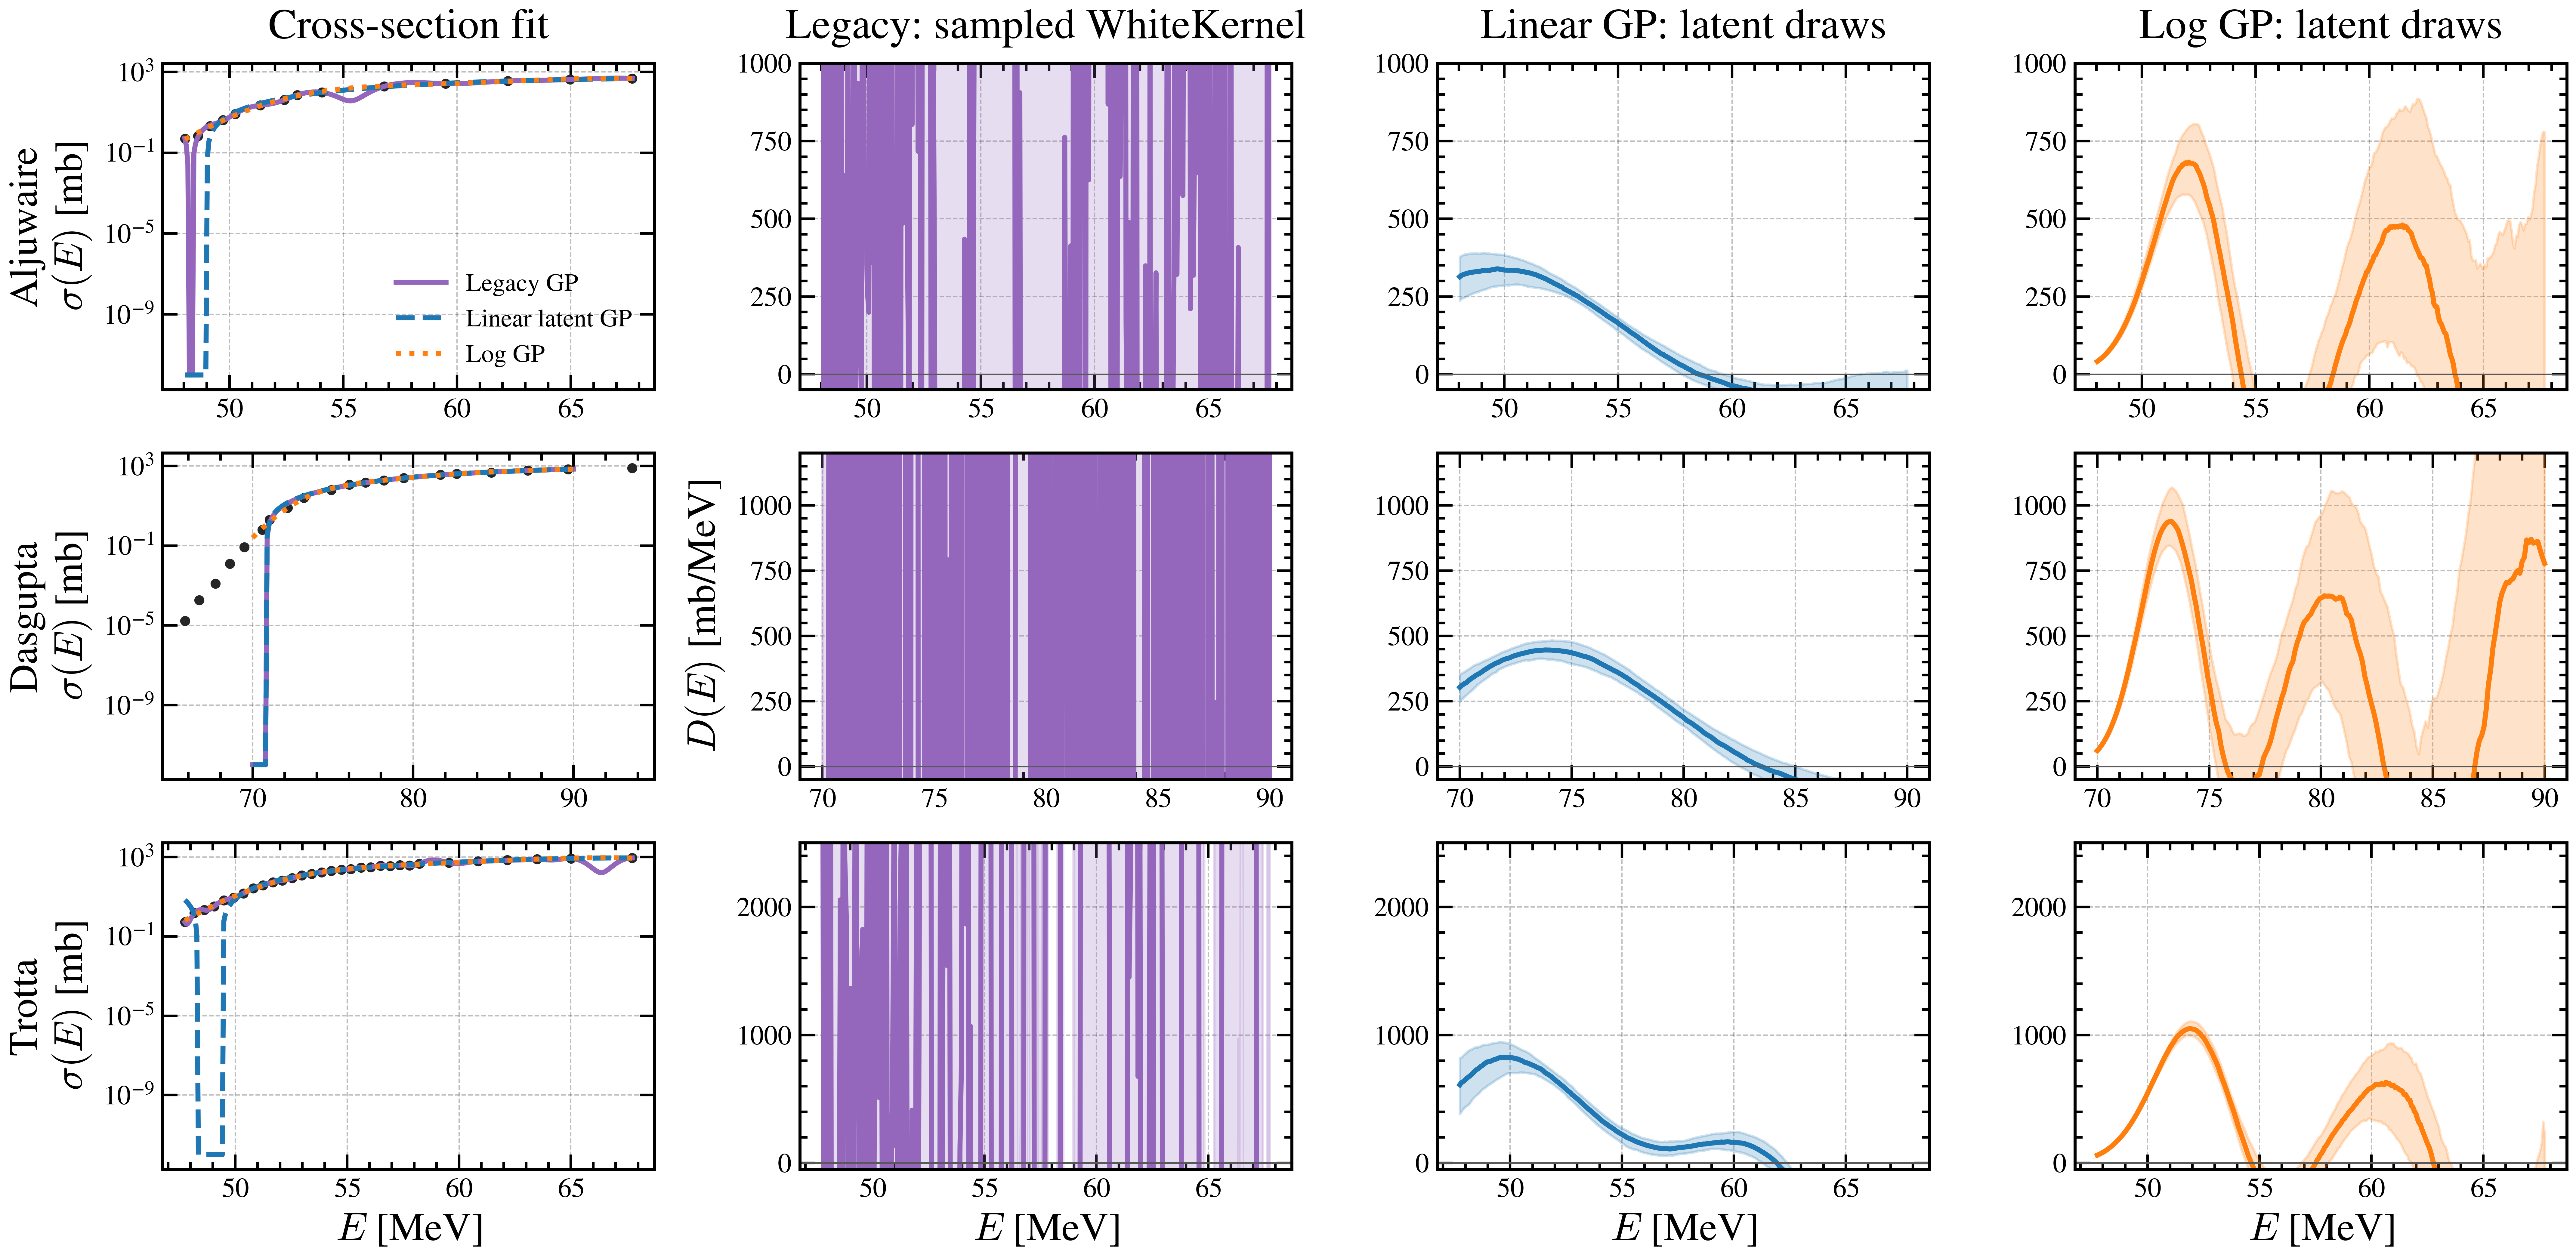

In [17]:
from sklearn.gaussian_process.kernels import ConstantKernel
from IPython.display import display

MISSING_ERROR_KEYS = {"Aljuwaire1984", "Dasgupta2007", "Trotta2001"}

def fit_linear_gp_unknown_absolute_error(E, y, n_restarts=10, random_state=17):
    """Empirical-Bayes linear GP with a learned constant absolute error in mb."""
    order = np.argsort(E)
    E, y = np.asarray(E)[order], np.asarray(y)[order]
    dE = np.diff(E)
    signal = ConstantKernel(max(np.var(y), 1e-4), (1e-6, 1e9)) * RBF(
        2*np.median(dE), (0.5*np.median(dE), max(10.0, 10*np.median(dE)))
    )
    y_scale = max(np.std(y), 1e-6)
    noise_fit = GaussianProcessRegressor(
        kernel=signal + WhiteKernel(
            (0.05*y_scale)**2,
            ((0.003*y_scale)**2, (0.50*y_scale)**2),
        ),
        alpha=1e-10, n_restarts_optimizer=n_restarts,
        normalize_y=False, random_state=random_state,
    ).fit(E[:, None], y)
    noise_var = float(noise_fit.kernel_.k2.noise_level)
    absolute_error = float(np.sqrt(noise_var))
    latent_gp = GaussianProcessRegressor(
        kernel=noise_fit.kernel_.k1,
        alpha=np.full(len(E), noise_var),
        optimizer=None, normalize_y=False, random_state=random_state,
    ).fit(E[:, None], y)
    return latent_gp, absolute_error, noise_fit

def fit_log_gp_unknown_fraction(E, y, n_restarts=10, random_state=17):
    order = np.argsort(E)
    E, y = np.asarray(E)[order], np.asarray(y)[order]
    log_y = np.log(y)
    dE = np.diff(E)
    signal = ConstantKernel(max(np.var(log_y), 1e-4), (1e-6, 1e4)) * RBF(
        2*np.median(dE), (0.5*np.median(dE), max(10.0, 10*np.median(dE)))
    )
    noise_bounds = tuple(np.log1p(np.array([0.003, 0.50])**2))
    noise_fit = GaussianProcessRegressor(
        kernel=signal + WhiteKernel(np.log1p(0.05**2), noise_bounds),
        alpha=1e-10, n_restarts_optimizer=n_restarts,
        normalize_y=False, random_state=random_state,
    ).fit(E[:, None], log_y)
    log_noise_var = float(noise_fit.kernel_.k2.noise_level)
    frac_error = float(np.sqrt(np.expm1(log_noise_var)))
    latent_gp = GaussianProcessRegressor(
        kernel=noise_fit.kernel_.k1,
        alpha=np.full(len(E), log_noise_var),
        optimizer=None, normalize_y=False, random_state=random_state,
    ).fit(E[:, None], log_y + 0.5*log_noise_var)
    return latent_gp, frac_error, noise_fit

def compare_missing_error_gp(spec, n_samples=200, random_state=19):
    E, y, err = load_experiment_data(spec)
    order = np.argsort(E)
    E, y, err = E[order], y[order], err[order]
    x = gpbarriers_prediction_grid(E, spec)
    legacy_gp, _ = train_gpbarriers_gp(E, y, err, spec)
    legacy_sigma = legacy_gp.predict(x[:, None])
    legacy_draws = legacy_gp.sample_y(x[:, None], n_samples, random_state=random_state).T
    linear_gp, absolute_error, linear_noise_fit = fit_linear_gp_unknown_absolute_error(
        E, y, random_state=random_state
    )
    linear_sigma = linear_gp.predict(x[:, None])
    linear_draws = linear_gp.sample_y(
        x[:, None], n_samples, random_state=random_state
    ).T
    log_gp, frac_error, noise_fit = fit_log_gp_unknown_fraction(E, y, random_state=random_state)
    log_sigma = np.exp(log_gp.predict(x[:, None]))
    log_draws = np.exp(log_gp.sample_y(x[:, None], n_samples, random_state=random_state).T)
    legacy_D = np.asarray([barrier_dist(x, z, acc=4) for z in legacy_draws])
    linear_D = np.asarray([barrier_dist(x, z, acc=4) for z in linear_draws])
    log_D = np.asarray([barrier_dist(x, z, acc=4) for z in log_draws])
    legacy_white_sd = np.sqrt(np.mean(np.diag(legacy_gp.kernel_.k2(E[:, None]))))
    return dict(E=E, y=y, x=x, legacy_sigma=legacy_sigma,
                linear_sigma=linear_sigma, log_sigma=log_sigma,
                legacy_D=legacy_D, linear_D=linear_D, log_D=log_D,
                absolute_error=absolute_error, frac_error=frac_error,
                legacy_white_sd=legacy_white_sd,
                legacy_kernel=str(legacy_gp.kernel_),
                linear_kernel=str(linear_noise_fit.kernel_),
                log_kernel=str(noise_fit.kernel_))

missing_specs = [s for s in EXPERIMENT_SPECS if s["key"] in MISSING_ERROR_KEYS]
missing_cases = {s["key"]: compare_missing_error_gp(s) for s in missing_specs}
summary = pd.DataFrame([dict(
    dataset=s["short_label"],
    legacy_predictive_white_sd_mb=missing_cases[s["key"]]["legacy_white_sd"],
    learned_absolute_error_mb=missing_cases[s["key"]]["absolute_error"],
    absolute_error_over_median_sigma=missing_cases[s["key"]]["absolute_error"] / np.median(missing_cases[s["key"]]["y"]),
    learned_fractional_error=missing_cases[s["key"]]["frac_error"],
    legacy_median_D_band_width=np.median(np.diff(np.percentile(missing_cases[s["key"]]["legacy_D"], [16, 84], axis=0), axis=0)),
    linear_median_D_band_width=np.median(np.diff(np.percentile(missing_cases[s["key"]]["linear_D"], [16, 84], axis=0), axis=0)),
    log_median_D_band_width=np.median(np.diff(np.percentile(missing_cases[s["key"]]["log_D"], [16, 84], axis=0), axis=0)),
) for s in missing_specs])
display(summary)

fig, axes = plt.subplots(3, 4, figsize=(14.5, 7.2), squeeze=False)
for row, spec in enumerate(missing_specs):
    c = missing_cases[spec["key"]]
    axes[row, 0].semilogy(c["E"], c["y"], "o", ms=3, color=DATA_COLOR)
    axes[row, 0].semilogy(c["x"], np.maximum(c["legacy_sigma"], 1e-12), color=GP_COLOR, label="Legacy GP")
    axes[row, 0].semilogy(c["x"], np.maximum(c["linear_sigma"], 1e-12), color=LINEAR_GP_COLOR, label="Linear latent GP")
    axes[row, 0].semilogy(c["x"], c["log_sigma"], color=LOG_GP_COLOR, label="Log GP")
    axes[row, 0].set_ylabel(spec["short_label"] + "\n$\\sigma(E)$ [mb]")
    for col, key, color in [
        (1, "legacy_D", GP_COLOR),
        (2, "linear_D", LINEAR_GP_COLOR),
        (3, "log_D", LOG_GP_COLOR),
    ]:
        lo, med, hi = np.percentile(c[key], [16, 50, 84], axis=0)
        axes[row, col].fill_between(c["x"], lo, hi, color=color, alpha=0.22)
        axes[row, col].plot(c["x"], med, color=color)
        axes[row, col].axhline(0, color="0.35", lw=0.6)
        axes[row, col].set_ylim(spec["ylims"])
    for ax in axes[row, :]:
        ax.grid(True, alpha=0.25)
        ax.tick_params(labelsize=11)
axes[0, 0].set_title("Cross-section fit", fontsize=17, pad=10)
axes[0, 1].set_title("Legacy: sampled WhiteKernel", fontsize=17, pad=10)
axes[0, 2].set_title("Linear GP: latent draws", fontsize=17, pad=10)
axes[0, 3].set_title("Log GP: latent draws", fontsize=17, pad=10)
axes[0, 0].legend(frameon=False, fontsize=10)
axes[1, 1].set_ylabel(r"$D(E)$ [mb/MeV]")
for ax in axes[-1, :]: ax.set_xlabel(r"$E$ [MeV]")
fig.tight_layout()
fig.savefig(PLOT_DIR / "experimental_missing_errors_legacy_vs_linear_log_gp.pdf", bbox_inches="tight")
fig.savefig(PLOT_DIR / "experimental_missing_errors_legacy_vs_linear_log_gp.png", bbox_inches="tight", dpi=300)
plt.show()


In [18]:
def train_log_fraction_experiment_gp(E_train, sigma_train, E_eval,
                                     n_samples=GP_N_SAMPLES, random_state=19):
    """Log-space GP with one inferred relative uncertainty and latent-function draws."""
    E_train = np.asarray(E_train, dtype=float)
    sigma_train = np.asarray(sigma_train, dtype=float)
    E_eval = np.asarray(E_eval, dtype=float)
    if np.any(sigma_train <= 0):
        raise ValueError("Log-space GP requires strictly positive cross sections.")

    latent_gp, frac_error, noise_fit = fit_log_gp_unknown_fraction(
        E_train, sigma_train,
        n_restarts=GP_N_RESTARTS,
        random_state=random_state,
    )

    # The learned log-noise variance has been added back as alpha in latent_gp.
    # Draw smooth latent log-functions, exponentiate, and only then differentiate.
    log_draws = latent_gp.sample_y(
        E_eval[:, None], n_samples=n_samples, random_state=random_state
    ).T
    sigma_samples = np.exp(log_draws)
    d_samples = np.asarray([
        barrier_dist(E_eval, sample, acc=4) for sample in sigma_samples
    ])
    d_mean = d_samples.mean(axis=0)
    d_median = np.median(d_samples, axis=0)
    d_low, d_high = np.percentile(d_samples, [16.0, 84.0], axis=0)

    return {
        "gp": latent_gp,
        "noise_fit": noise_fit,
        "frac_error": frac_error,
        "E_eval": E_eval,
        "d_mean": d_mean,
        "d_median": d_median,
        "d_std": d_samples.std(axis=0),
        "d_low": d_low,
        "d_high": d_high,
    }


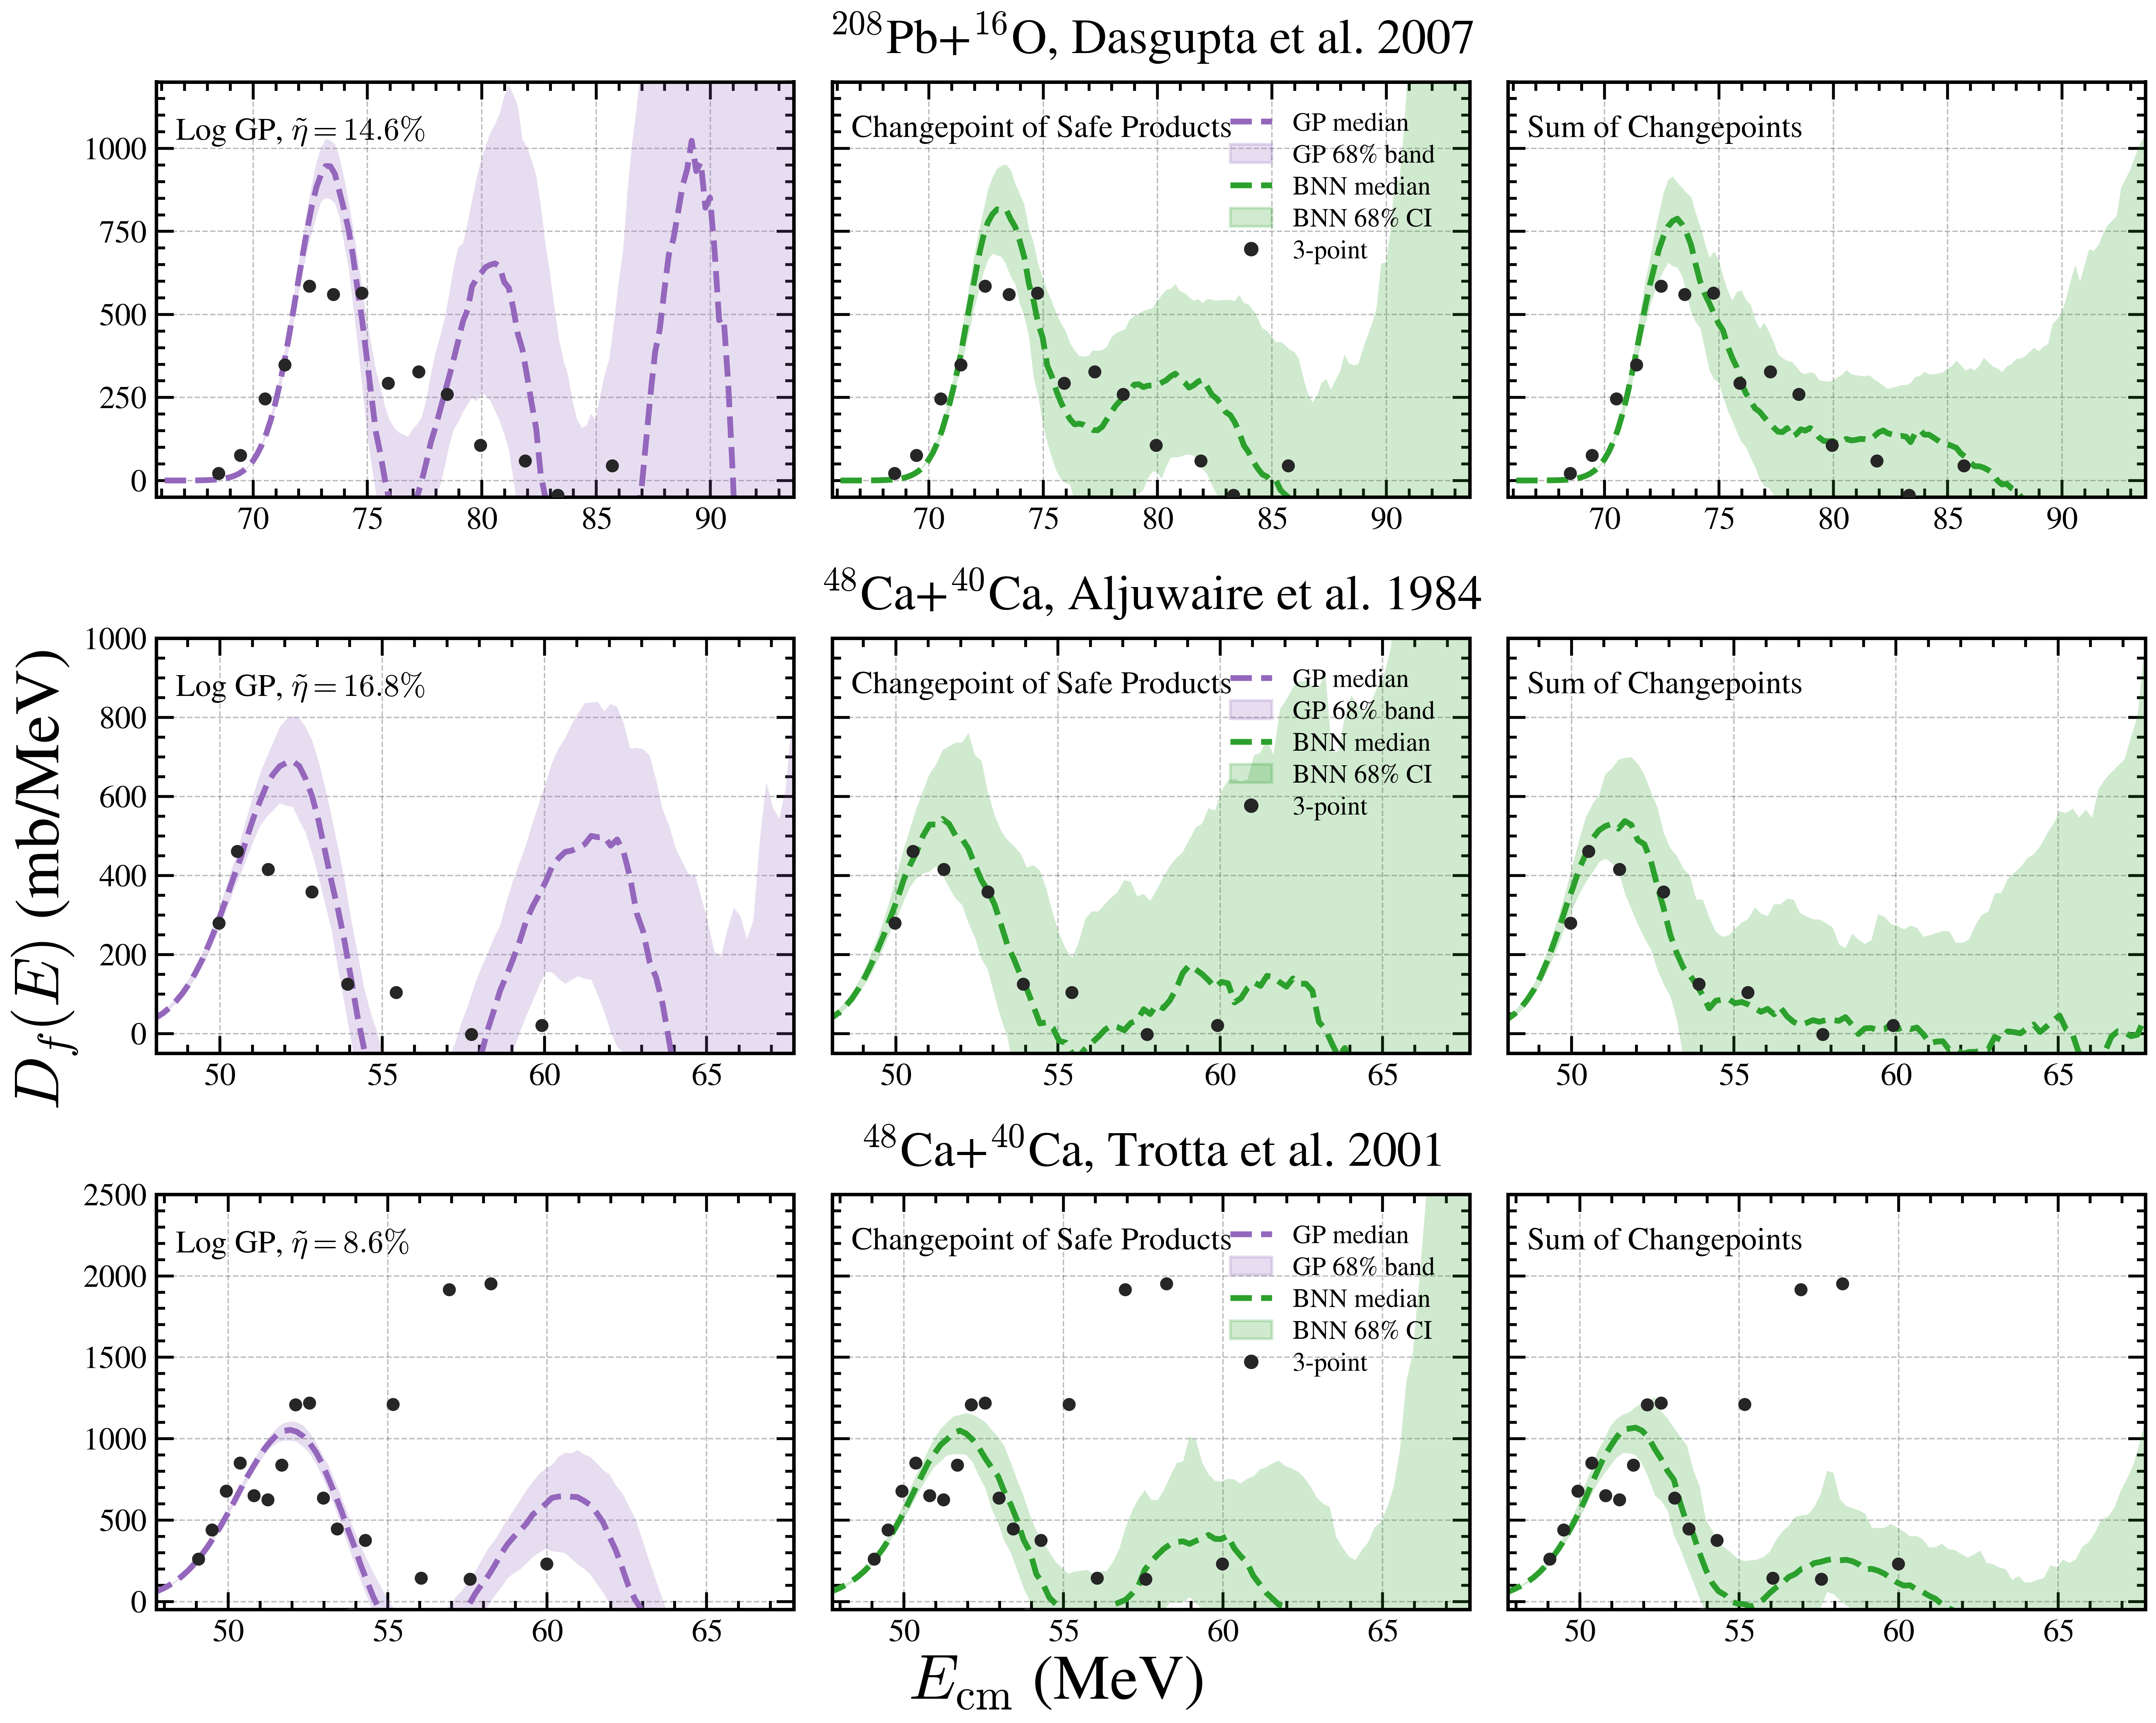

In [19]:
plot_experiment_collection(
    remaining_three_specs,
    outfile=PLOT_DIR / "experiments7_d3lam1e1_last3_log_gp_3x3.png",
    gp_strategy="log_unknown_fraction",
)


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/

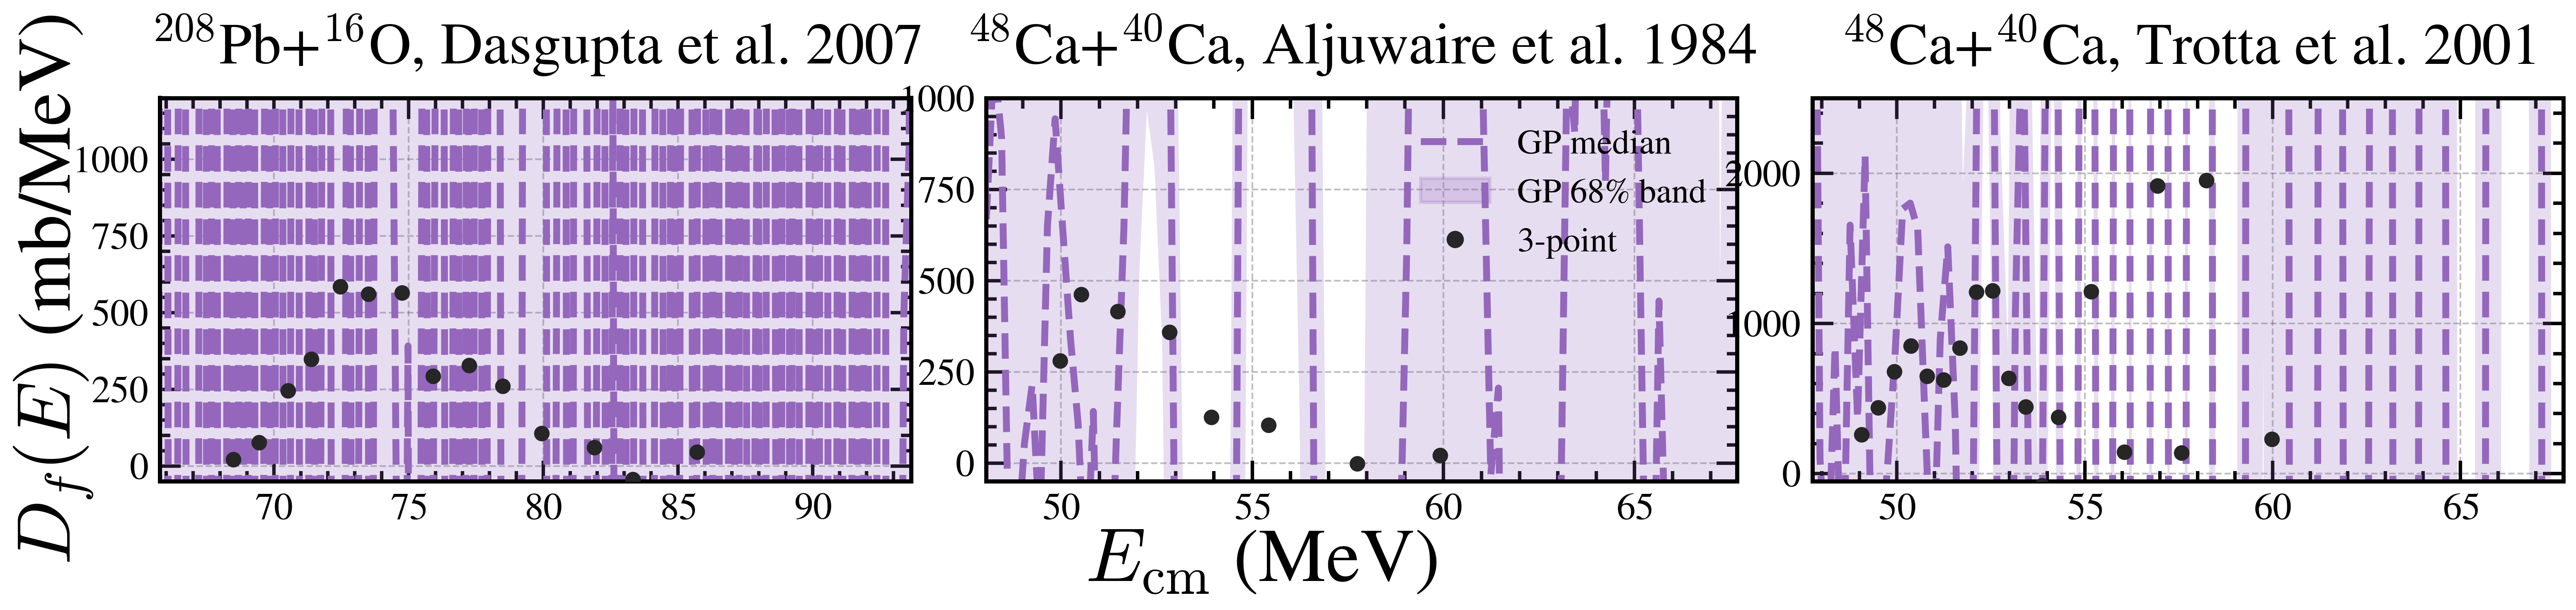

In [20]:
# Legacy GP diagnostic before inferring a relative uncertainty.
fig, axes = plt.subplots(1, 3, figsize=(10.8, 2.75), squeeze=False)
axes = axes.ravel()
fig.subplots_adjust(left=0.09, right=0.985, bottom=0.22, top=0.78, wspace=0.10)

for ax, spec in zip(axes, remaining_three_specs):
    E_train, sigma_train, error_train = load_experiment_data(spec)
    bnn_case = load_experiments7_bnn_case(spec["key"])
    E_eval = bnn_case["E_pred_by_model"][MODEL_SPECS[0][0]]
    gp_case = train_experiment_gp(
        E_train, sigma_train, error_train, spec, E_eval
    )

    E_barrier, dist, err = paper_three_point_barrier(
        E_train, sigma_train, error_train, dE=3
    )
    ax.plot(
        gp_case["E_eval"], gp_case["d_median"],
        lw=2.0, ls="--", color=GP_COLOR,
    )
    ax.fill_between(
        gp_case["E_eval"], gp_case["d_low"], gp_case["d_high"],
        color=GP_COLOR, alpha=BAND_ALPHA, linewidth=0,
    )
    plot_finite_difference_points(
        ax, E_barrier, dist, err, error_train, spec, dE=3
    )
    ax.set_xlim(spec["xlims"] or [E_train.min(), E_train.max()])
    ax.set_ylim(spec["ylims"])
    ax.set_title(f'{spec["system"]}, {spec["label"]}', fontsize=17, pad=10)
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=11)

legacy_gp_handles = [
    plt.Line2D([], [], color=GP_COLOR, lw=2.0, ls="--", label="GP median"),
    plt.Rectangle((0, 0), 1, 1, color=GP_COLOR, alpha=BAND_ALPHA, label="GP 68% band"),
    plt.Line2D([], [], marker="o", color=DATA_COLOR, lw=0, markersize=4, label="3-point"),
]
axes[1].legend(
    handles=legacy_gp_handles, loc="upper right",
    frameon=False, fontsize=10,
)
fig.supylabel(r"$D_f(E)$ (mb/MeV)", fontsize=SHARED_LABEL_FONTSIZE, x=0.035)
fig.supxlabel(r"$E_{\mathrm{cm}}$ (MeV)", fontsize=SHARED_LABEL_FONTSIZE, y=0.05)
fig.savefig(
    PLOT_DIR / "experiments7_d3lam1e1_missing_errors_legacy_gp_1x3.png",
    dpi=300, bbox_inches="tight",
)
plt.show()
plt.close(fig)
